In [1]:
import requests
import pandas as pd
import os
from dotenv import load_dotenv
load_dotenv()
api_key = os.getenv("COINGECKO_API_KEY")
url = "https://api.coingecko.com/api/v3/coins/markets"
params = {
    "vs_currency": "usd",
    "order": "market_cap_desc",
    "per_page": 25,
    "page": 1,
    "sparkline": False,
    "price_change_percentage": "1h,24h,7d,14d,30d,200d,1y"
}
headers = {
    "x-cg-demo-api-key": api_key
}
response = requests.get(
    url,
    headers=headers,
    params=params
)
print("Status Code:", response.status_code)
if response.status_code == 200:
    data = response.json()
    print("Data collected successfully.")
else:
    print("Error:", response.text)
df = pd.json_normalize(data)
df["timestamp"] = pd.Timestamp.now(tz="UTC")
columns = [
    "id",
    "symbol",
    "name",
    "current_price",
    "market_cap",
    "market_cap_rank",
    "total_volume",
    "price_change_percentage_24h",
    "price_change_percentage_1h_in_currency",
    "price_change_percentage_7d_in_currency",
    "price_change_percentage_14d_in_currency",
    "price_change_percentage_30d_in_currency",
    "price_change_percentage_200d_in_currency",
    "price_change_percentage_1y_in_currency",
    "timestamp"
]
df = df[columns]
df = df.rename(columns={
    "current_price": "price",
    "total_volume": "volume",
    "price_change_percentage_24h": "change_24h",
    "price_change_percentage_1h_in_currency": "change_1h",
    "price_change_percentage_7d_in_currency": "change_7d",
    "price_change_percentage_14d_in_currency": "change_14d",
    "price_change_percentage_30d_in_currency": "change_30d",
    "price_change_percentage_200d_in_currency": "change_200d",
    "price_change_percentage_1y_in_currency": "change_1y"
})
print("Rows:", len(df))
print("Columns:", len(df.columns))
df.head()

Status Code: 200
Data collected successfully.
Rows: 25
Columns: 15


,id,symbol,name,price,market_cap,market_cap_rank,volume,change_24h,change_1h,change_7d,change_14d,change_30d,change_200d,change_1y,timestamp
0,bitcoin,btc,Bitcoin,84799.000000,1703792962500,1,20533858033,0.78308,0.1351,5.8187,10.5591,6.7742,21.9816,-22.3340,2026-09-27 10:54:28.679766+00:00
1,ethereum,eth,Ethereum,2708.740000,330712382164,2,7221285862,0.80527,0.0043,5.4465,8.8326,9.0827,34.2273,-31.9315,2026-09-27 10:54:28.679766+00:00
2,tether,usdt,Tether,0.999781,183781079940,3,40390466162,-0.00770,-0.0006,0.0220,0.0051,-0.0262,-0.0131,-0.0684,2026-09-27 10:54:28.679766+00:00
3,binancecoin,bnb,BNB,779.040000,103759099793,4,686799716,0.71643,0.1825,4.1545,8.6327,10.5394,21.5230,-19.4175,2026-09-27 10:54:28.679766+00:00
4,ripple,xrp,XRP,1.540000,96568133192,5,2783390331,-0.91988,0.2125,11.7373,14.1212,8.2997,11.3997,-44.5065,2026-09-27 10:54:28.679766+00:00


In [2]:
import time

def collect_crypto_data():

    response = requests.get(
        url,
        headers=headers,
        params=params
    )

    if response.status_code != 200:
        print("Error:", response.status_code)
        return None
    data = response.json()
    df_new = pd.json_normalize(data)
    df_new["timestamp"] = pd.Timestamp.now(tz="UTC")
    df_new = df_new[columns]
    df_new = df_new.rename(columns={
        "current_price": "price",
        "total_volume": "volume",
        "price_change_percentage_24h": "change_24h",
        "price_change_percentage_1h_in_currency": "change_1h",
        "price_change_percentage_7d_in_currency": "change_7d",
        "price_change_percentage_14d_in_currency": "change_14d",
        "price_change_percentage_30d_in_currency": "change_30d",
        "price_change_percentage_200d_in_currency": "change_200d",
        "price_change_percentage_1y_in_currency": "change_1y"
    })

    return df_new

In [27]:
historical_df = pd.DataFrame()
num_snapshots = 9
interval = 30
for i in range(num_snapshots):
    print(f"Collecting snapshot {i + 1}/{num_snapshots}...")
    snapshot = collect_crypto_data()
    if snapshot is not None:
        historical_df = pd.concat(
            [historical_df, snapshot],
            ignore_index=True
        )
        print("Rows collected:", len(historical_df))
    if i < num_snapshots - 1:
        print("Waiting 5 minutes...")
        time.sleep(interval)

Rows collected: 25
Waiting 5 minutes...
Rows collected: 50
Waiting 5 minutes...
Rows collected: 75
Waiting 5 minutes...
Rows collected: 100
Waiting 5 minutes...
Rows collected: 125
Waiting 5 minutes...
Rows collected: 150
Waiting 5 minutes...
Rows collected: 175
Waiting 5 minutes...
Rows collected: 200
Waiting 5 minutes...
Rows collected: 225


In [28]:
historical_df.to_csv(
    "crypto_historical_data.csv",
    index=False
)
print("Historical data saved successfully.")
print(os.getcwd())

Historical data saved successfully.
C:\Users\sshas


In [14]:
latest=historical_df[historical_df['timestamp']==historical_df['timestamp'].max()].copy()
marketcap= latest.sort_values("market_cap",ascending=False)
print("Top 10 Coins by Market Cap")
marketcap[
    ["name", "market_cap", "market_cap_rank"]
].head(10)

Top 10 Coins by Market Cap


,name,market_cap,market_cap_rank
50,Bitcoin,1704700162112,1
51,Ethereum,330760037093,2
52,Tether,183780805177,3
53,BNB,103668462315,4
54,XRP,96645625901,5
55,USDC,75193743261,6
56,Solana,72848190116,7
57,TRON,31707148099,8
58,Zcash,28172196532,9
59,Figure Heloc,24610425446,10


In [15]:
top_volume = latest.sort_values(
    "volume",
    ascending=False
)
print("Top 10 Coins by Volume")
top_volume[
    ["name", "volume", "market_cap"]
].head(10)

Top 10 Coins by Volume


,name,volume,market_cap
52,Tether,40364216521,183780805177
50,Bitcoin,20561697323,1704700162112
55,USDC,9144910706,75193743261
51,Ethereum,7093332110,330760037093
56,Solana,3533888929,72848190116
54,XRP,2600515430,96645625901
58,Zcash,1289305451,28172196532
71,NEAR Protocol,1177712928,6801210895
53,BNB,699356503,103668462315
61,Dogecoin,679518450,15232407289


In [16]:
top_gainers = latest.sort_values(
    "change_24h",
    ascending=False
)
print('Top 10 Gainers in 24 hours')
top_gainers[
    ["name", "change_24h"]
].head(10)

Top 10 Gainers in 24 hours


,name,change_24h
58,Zcash,8.34427
71,NEAR Protocol,5.89810
67,Rain,5.58462
72,Uniswap,3.76732
59,Figure Heloc,3.68430
56,Solana,2.86737
74,Canton,2.12483
60,Hyperliquid,1.15418
62,Chainlink,1.13695
64,WhiteBIT Coin,0.90473


In [18]:
top_gainers = latest.sort_values(
    "change_24h",
    ascending=True
)
print("Top 10 losers in 24 hours.")
top_gainers[
    ["name", "change_24h"]
].head(10)

Top 10 losers in 24 hours.


,name,change_24h
73,Litecoin,-3.04326
69,Stellar,-0.97687
54,XRP,-0.86744
57,TRON,-0.86612
66,Cardano,-0.45192
61,Dogecoin,-0.28115
70,Bitcoin Cash,-0.14923
65,USDS,-0.01359
55,USDC,-0.00477
52,Tether,-0.00438


In [19]:
top10 = latest.sort_values(
    "market_cap_rank"
).head(10)
print('Top 10 Coins performance across different periods.')
performance = top10[
    [
        "name",
        "change_1h",
        "change_7d",
        "change_14d",
        "change_30d",
        "change_200d",
        "change_1y"
    ]
]

performance

Top 10 Coins performance across different periods.


,name,change_1h,change_7d,change_14d,change_30d,change_200d,change_1y
50,Bitcoin,-0.0775,5.4609,10.4969,6.9887,22.1695,-22.4059
51,Ethereum,-0.1866,5.0370,9.0442,8.8060,34.1993,-32.2171
52,Tether,0.0009,0.0235,0.0070,-0.0260,-0.0137,-0.0675
53,BNB,-0.1608,3.7648,8.7142,10.5087,21.6840,-19.6289
54,XRP,-0.0416,11.1643,14.3830,9.0152,11.2530,-44.7432
55,USDC,0.0012,0.0206,0.0099,-0.0120,0.0024,0.0251
56,Solana,-0.3962,14.4990,24.1567,17.0093,45.7975,-38.4153
57,TRON,0.0674,-2.3197,-1.8644,-1.5938,15.8072,-0.8750
58,Zcash,-0.1848,15.2531,52.8993,109.8729,683.2563,2887.9447
59,Figure Heloc,0.0021,5.9953,6.1405,2.4243,2.4627,3.5734


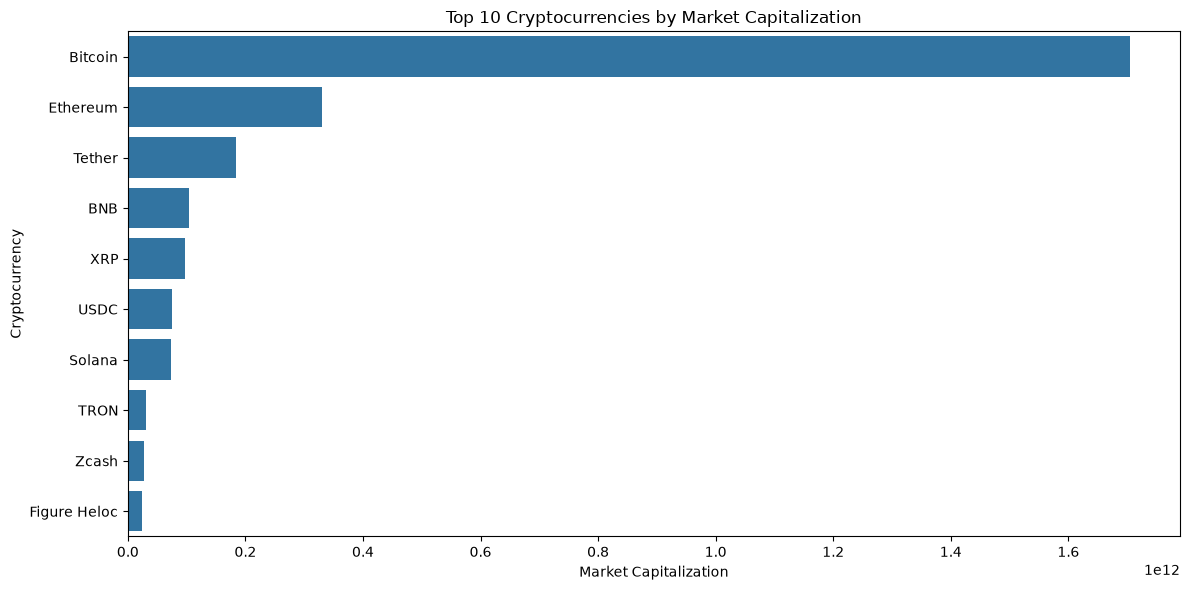

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns
top10 = latest.sort_values(
    "market_cap",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top10,
    x="market_cap",
    y="name"
)

plt.title("Top 10 Cryptocurrencies by Market Capitalization")
plt.xlabel("Market Capitalization")
plt.ylabel("Cryptocurrency")

plt.tight_layout()
plt.show()

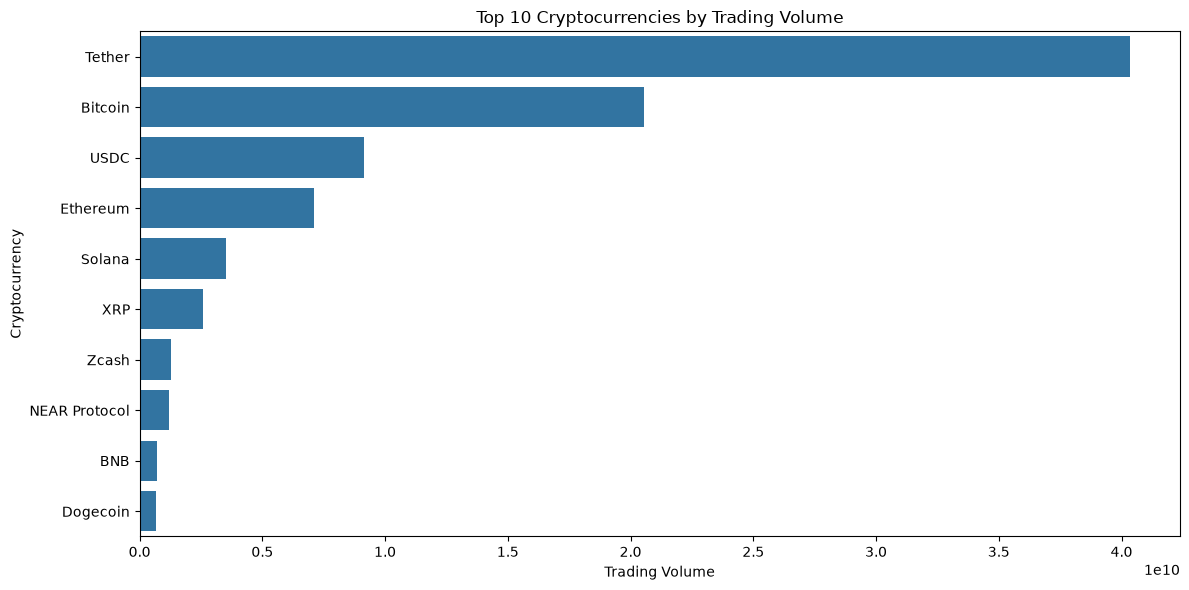

In [21]:
top_volume = latest.sort_values(
    "volume",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_volume,
    x="volume",
    y="name"
)

plt.title("Top 10 Cryptocurrencies by Trading Volume")
plt.xlabel("Trading Volume")
plt.ylabel("Cryptocurrency")

plt.tight_layout()
plt.show()

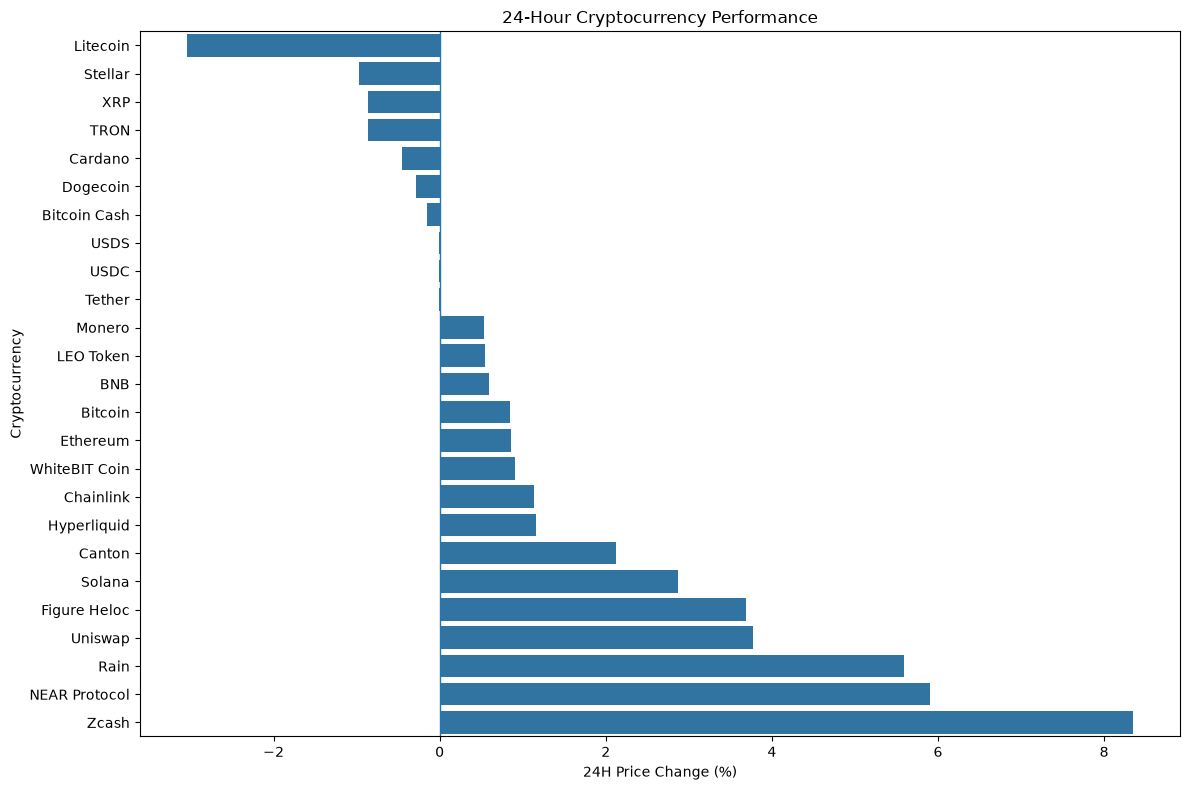

In [22]:
performance_24h = latest.sort_values(
    "change_24h"
)

plt.figure(figsize=(12, 8))

sns.barplot(
    data=performance_24h,
    x="change_24h",
    y="name"
)

plt.axvline(0, linewidth=1)

plt.title("24-Hour Cryptocurrency Performance")
plt.xlabel("24H Price Change (%)")
plt.ylabel("Cryptocurrency")

plt.tight_layout()
plt.show()

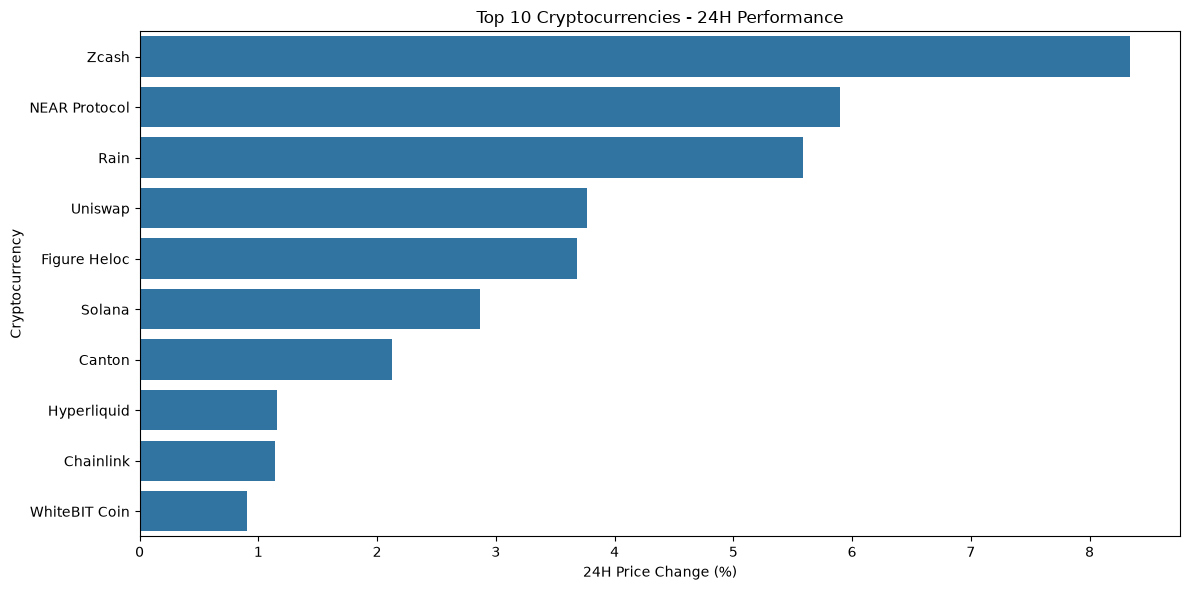

In [24]:
performance_24h = latest.sort_values(
    "change_24h",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=performance_24h,
    x="change_24h",
    y="name"
)

plt.title("Top 10 Cryptocurrencies - 24H Performance")
plt.xlabel("24H Price Change (%)")
plt.ylabel("Cryptocurrency")

plt.tight_layout()
plt.show()

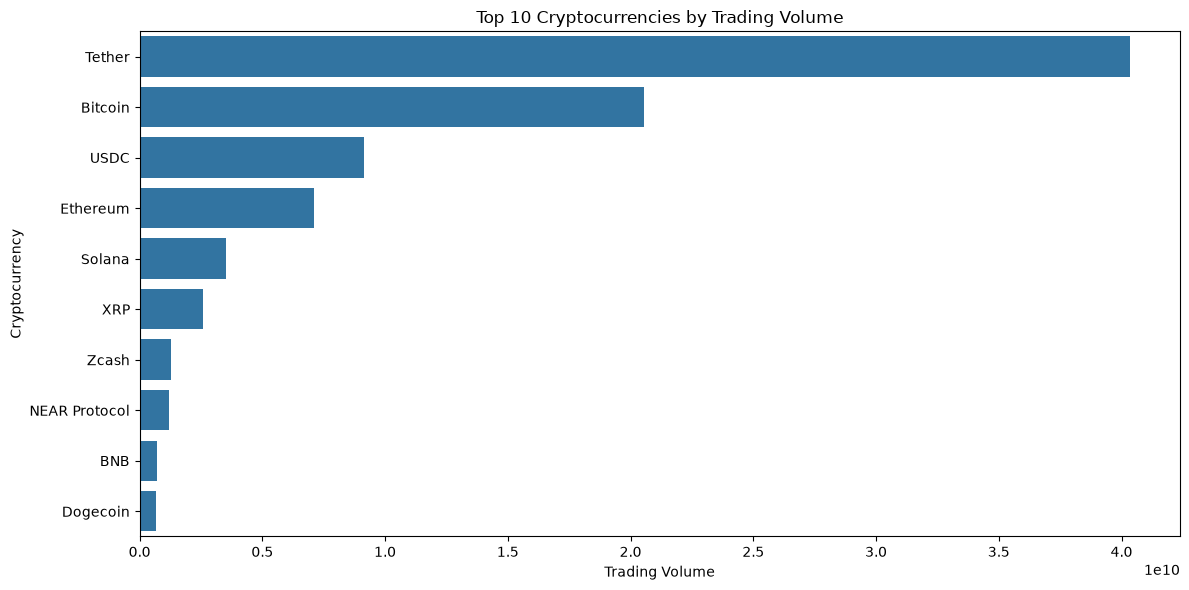

In [25]:
top_volume = latest.sort_values(
    "volume",
    ascending=False
).head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_volume,
    x="volume",
    y="name"
)

plt.title("Top 10 Cryptocurrencies by Trading Volume")
plt.xlabel("Trading Volume")
plt.ylabel("Cryptocurrency")

plt.tight_layout()
plt.show()

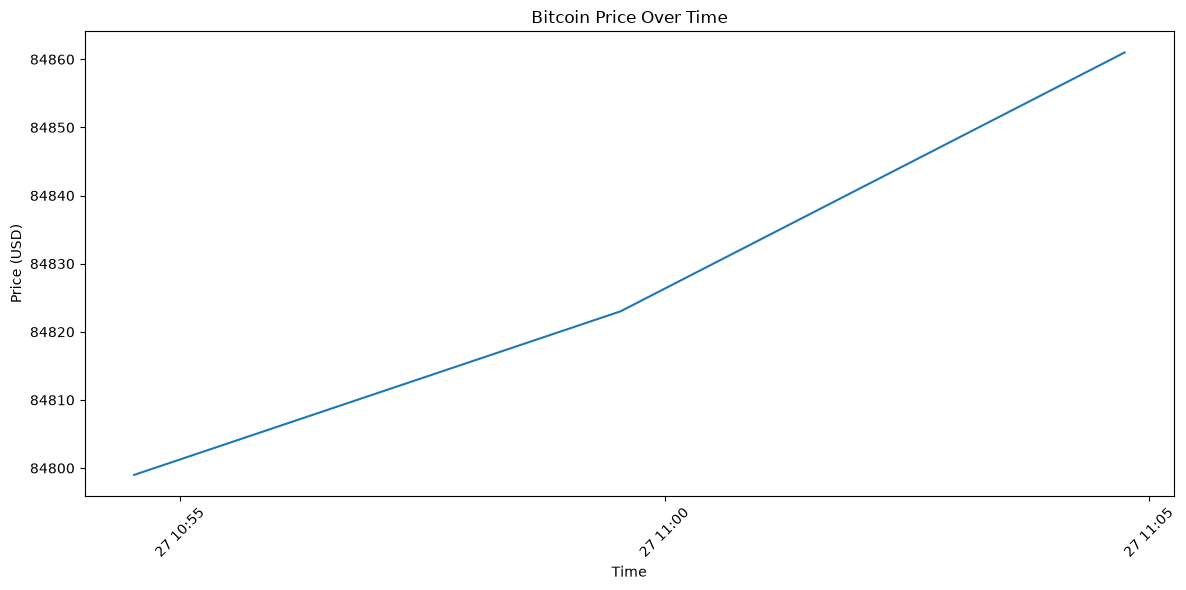

In [26]:
top_coin = latest.sort_values(
    "market_cap_rank"
).iloc[0]["id"]

coin_history = historical_df[
    historical_df["id"] == top_coin
].sort_values("timestamp")

plt.figure(figsize=(12, 6))

plt.plot(
    coin_history["timestamp"],
    coin_history["price"]
)

plt.title(f"{coin_history['name'].iloc[0]} Price Over Time")
plt.xlabel("Time")
plt.ylabel("Price (USD)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [31]:
print(historical_df.shape)

(225, 15)
